In [1]:
!pip install pandas numpy matplotlib seaborn scipy streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 20.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 52.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [4]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Data Understanding

The dataset contains information about residential houses, including their area, quality, construction year, number of rooms and selling prices. This step helps us understand the structure and characteristics of the data.

In [5]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (1460, 81)

First 5 Rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null  

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



Column Names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'Pool

In [6]:
print("Total Missing Values:", df.isnull().sum().sum())

print("\nColumns with Missing Values:")
display(df.isnull().sum()[df.isnull().sum() > 0].sort_values(ascending=False))

print("\nDuplicate Rows:", df.duplicated().sum())

Total Missing Values: 7829

Columns with Missing Values:


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81



Duplicate Rows: 0


In [7]:
print("Mean Sale Price:", df["SalePrice"].mean())
print("Median Sale Price:", df["SalePrice"].median())
print("Mode Sale Price:", df["SalePrice"].mode()[0])
print("Minimum Sale Price:", df["SalePrice"].min())
print("Maximum Sale Price:", df["SalePrice"].max())
print("Standard Deviation:", df["SalePrice"].std())
print("Variance:", df["SalePrice"].var())
print("Skewness:", df["SalePrice"].skew())

Mean Sale Price: 180921.19589041095
Median Sale Price: 163000.0
Mode Sale Price: 140000
Minimum Sale Price: 34900
Maximum Sale Price: 755000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Skewness: 1.8828757597682129


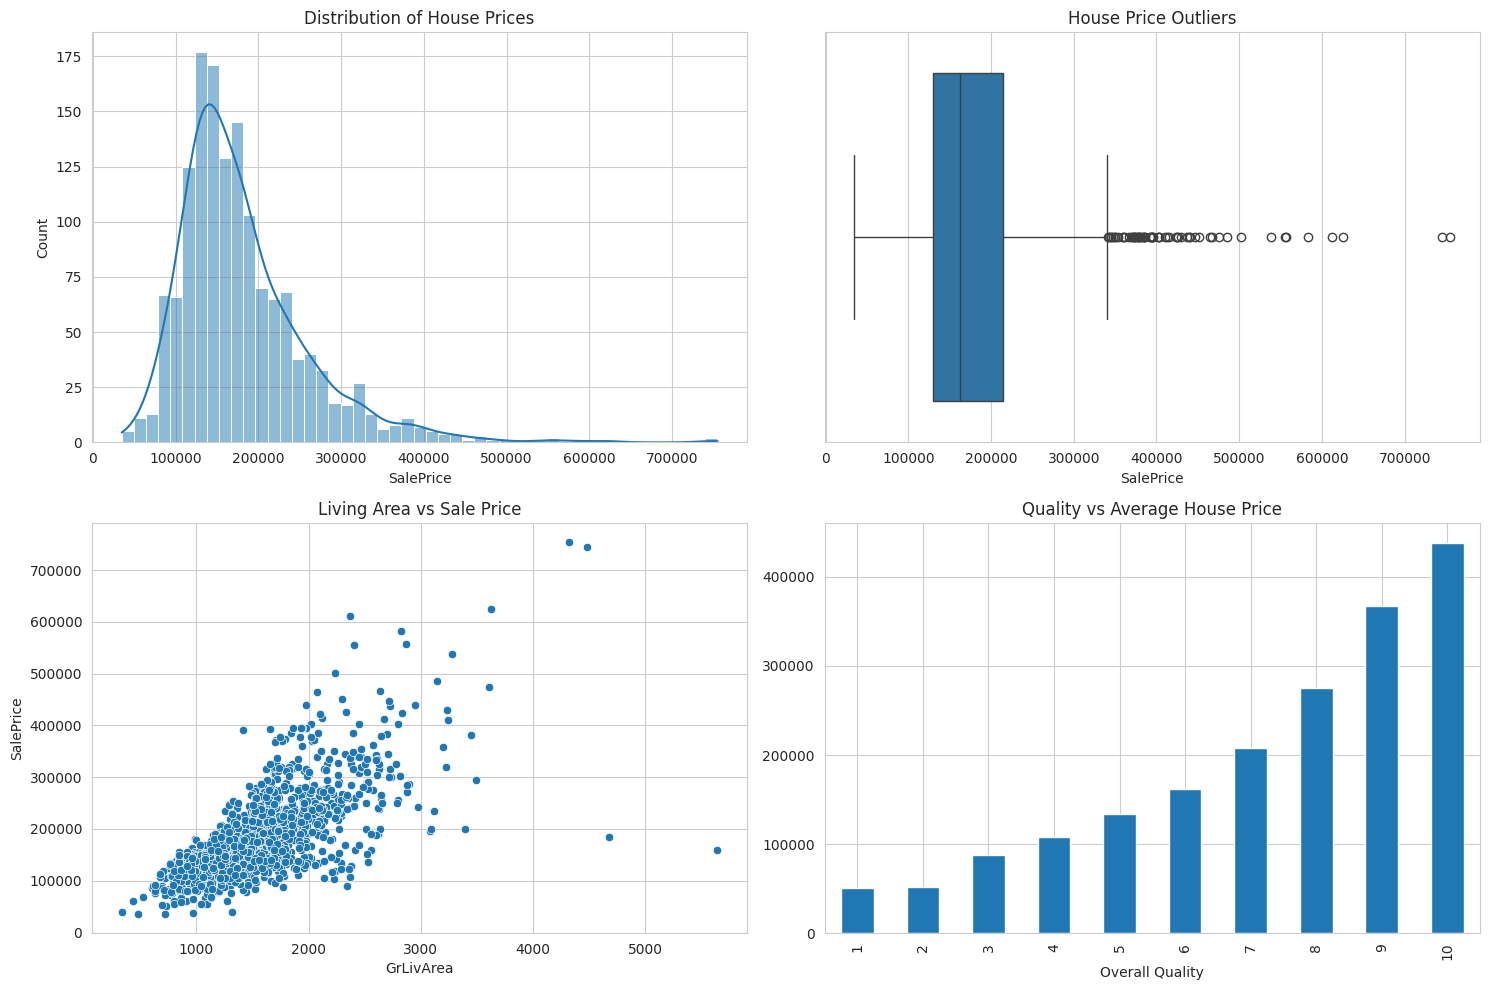

In [8]:
plt.figure(figsize=(15, 10))

# 1. Histogram
plt.subplot(2, 2, 1)
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of House Prices")

# 2. Boxplot
plt.subplot(2, 2, 2)
sns.boxplot(x=df["SalePrice"])
plt.title("House Price Outliers")

# 3. Scatter Plot
plt.subplot(2, 2, 3)
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"])
plt.title("Living Area vs Sale Price")

# 4. Bar Chart
plt.subplot(2, 2, 4)
df.groupby("OverallQual")["SalePrice"].mean().plot(kind="bar")
plt.title("Quality vs Average House Price")
plt.xlabel("Overall Quality")

plt.tight_layout()
plt.show()

Top 10 Features Related to SalePrice:


,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


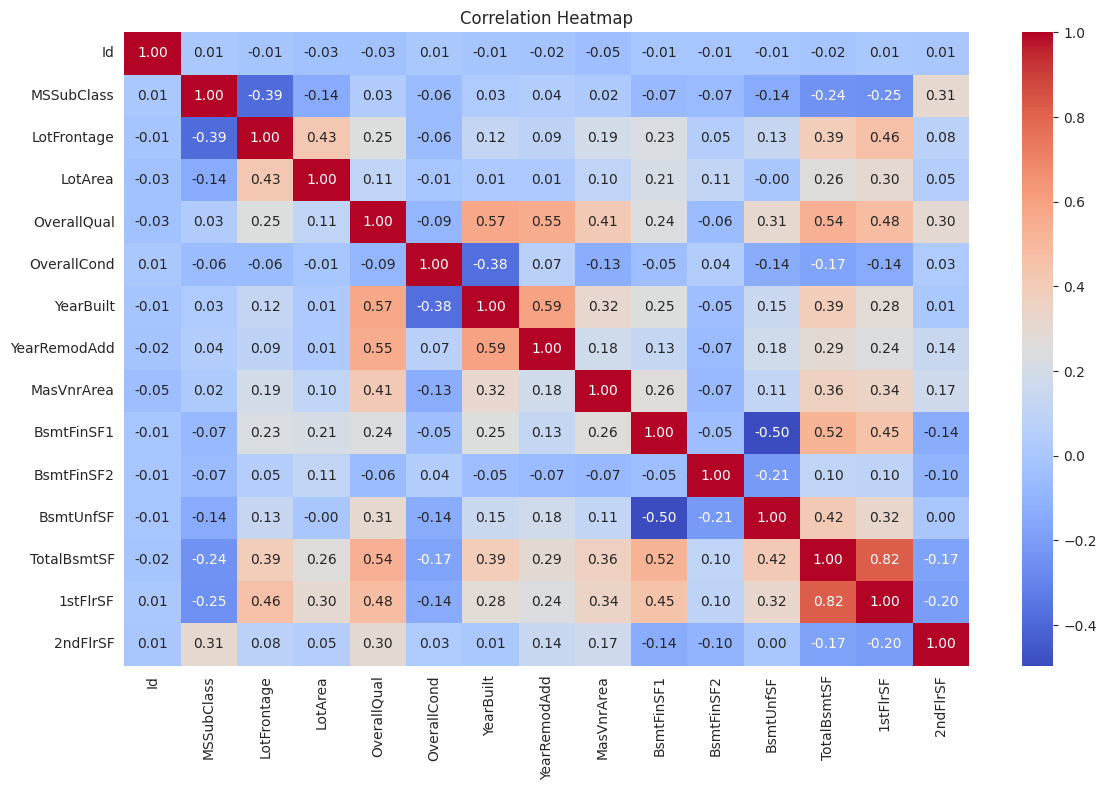

In [9]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

print("Top 10 Features Related to SalePrice:")
display(correlation["SalePrice"].sort_values(ascending=False).head(10))

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation.iloc[:15, :15],
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [10]:
Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["SalePrice"] < lower) |
    (df["SalePrice"] > upper)
]

print("Number of Outliers:", len(outliers))
print("Lower Limit:", lower)
print("Upper Limit:", upper)

Number of Outliers: 61
Lower Limit: 3937.5
Upper Limit: 340037.5


In [11]:
clean_df = df.copy()

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Fill numerical missing values with median
for col in clean_df.select_dtypes(include=np.number).columns:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# Fill categorical missing values with mode
for col in clean_df.select_dtypes(include="object").columns:
    if clean_df[col].isnull().sum() > 0:
        clean_df[col] = clean_df[col].fillna(clean_df[col].mode()[0])

print("Data Cleaning Completed!")
print("Remaining Missing Values:", clean_df.isnull().sum().sum())
print("Cleaned Dataset Shape:", clean_df.shape)

Data Cleaning Completed!
Remaining Missing Values: 0
Cleaned Dataset Shape: (1460, 81)


Observations:
1. Most houses are sold within the lower-to-middle price range.
2. The SalePrice distribution is positively skewed.
3. Houses with larger living areas generally have higher selling prices.
4. Houses with better overall quality tend to have higher average prices.
5. Some unusually high house prices can be observed as potential outliers.

In [12]:
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", clean_df.shape)

print("Missing Values:", clean_df.isnull().sum().sum())
print("Duplicate Rows:", clean_df.duplicated().sum())

Original Dataset: (1460, 81)
Cleaned Dataset: (1460, 81)
Missing Values: 0
Duplicate Rows: 0


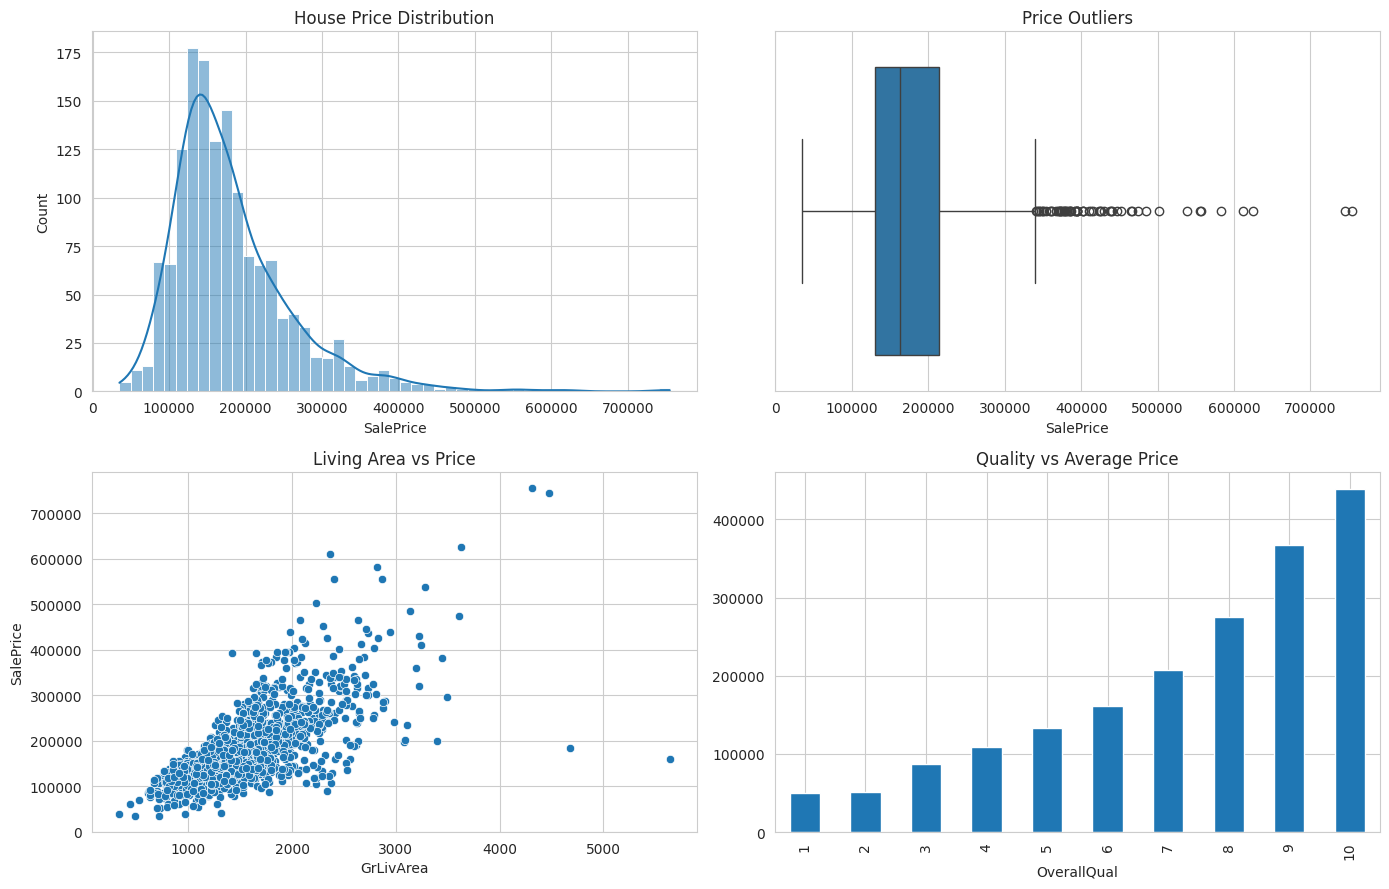

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("House Price Distribution")

sns.boxplot(x=df["SalePrice"], ax=axes[0, 1])
axes[0, 1].set_title("Price Outliers")

sns.scatterplot(
    x=df["GrLivArea"],
    y=df["SalePrice"],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Living Area vs Price")

df.groupby("OverallQual")["SalePrice"].mean().plot(
    kind="bar", ax=axes[1, 1]
)
axes[1, 1].set_title("Quality vs Average Price")

plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=150)
plt.show()

In [14]:
app_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(
    page_title="House Price EDA Dashboard",
    page_icon="🏠",
    layout="wide"
)

@st.cache_data
def load_data():
    return pd.read_csv("train.csv")

df = load_data()

st.title("🏠 House Price Exploratory Data Analysis")
st.write("An interactive dashboard to explore housing data and discover price patterns.")

st.sidebar.header("Dashboard Filters")

quality = st.sidebar.multiselect(
    "Select Overall Quality",
    sorted(df["OverallQual"].dropna().unique()),
    default=sorted(df["OverallQual"].dropna().unique())
)

filtered = df[df["OverallQual"].isin(quality)]

st.subheader("Dataset Overview")

c1, c2, c3, c4 = st.columns(4)

c1.metric("Total Houses", f"{len(filtered):,}")
c2.metric("Average Price", f"${filtered['SalePrice'].mean():,.0f}")
c3.metric("Median Price", f"${filtered['SalePrice'].median():,.0f}")
c4.metric("Average Living Area", f"{filtered['GrLivArea'].mean():,.0f} sq ft")

st.divider()

st.subheader("House Price Distribution")

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(filtered["SalePrice"], kde=True, ax=ax)
ax.set_xlabel("Sale Price ($)")
ax.set_title("Distribution of House Prices")
st.pyplot(fig)
plt.close(fig)

col1, col2 = st.columns(2)

with col1:
    st.subheader("Living Area vs Sale Price")
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.scatterplot(
        data=filtered,
        x="GrLivArea",
        y="SalePrice",
        ax=ax
    )
    ax.set_title("Living Area vs Sale Price")
    st.pyplot(fig)
    plt.close(fig)

with col2:
    st.subheader("Quality vs Average Price")
    quality_price = filtered.groupby("OverallQual")["SalePrice"].mean()
    fig, ax = plt.subplots(figsize=(7, 4))
    quality_price.plot(kind="bar", ax=ax)
    ax.set_xlabel("Overall Quality")
    ax.set_ylabel("Average Sale Price ($)")
    st.pyplot(fig)
    plt.close(fig)

st.divider()

st.subheader("Correlation Heatmap")

numeric = filtered.select_dtypes(include=np.number)
selected = [
    col for col in [
        "SalePrice", "OverallQual", "GrLivArea",
        "GarageCars", "TotalBsmtSF", "YearBuilt",
        "FullBath", "LotArea"
    ] if col in numeric.columns
]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    numeric[selected].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    ax=ax
)
st.pyplot(fig)
plt.close(fig)

st.divider()

st.subheader("Dataset Information")
st.write("Number of rows:", filtered.shape[0])
st.write("Number of columns:", filtered.shape[1])
st.write("Missing values:", int(filtered.isnull().sum().sum()))

with st.expander("View Dataset"):
    st.dataframe(filtered.head(100))

st.download_button(
    "Download Filtered Dataset",
    data=filtered.to_csv(index=False),
    file_name="house_price_data.csv",
    mime="text/csv"
)

st.success("House Price EDA Dashboard loaded successfully!")
'''

with open("app.py", "w") as f:
    f.write(app_code)

requirements = """streamlit
pandas
numpy
matplotlib
seaborn
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("app.py created successfully!")
print("requirements.txt created successfully!")

app.py created successfully!
requirements.txt created successfully!


In [15]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>